# Conciliar un balance de flotación sin inventar certeza

**Pregunta:** ¿Cómo conciliamos las observaciones de alimentación, concentrado y relaves de una misma parcela
de flotación, y qué cambia al confiar menos en el medidor de alimentación?

Nivel 1 · Requisitos: arreglos de Python y significado de toneladas por hora. · Lectura: 25 minutos.

## Objetivos

Un banco de flotación divide los sólidos secos entre concentrado y relaves. Tres medidores rara vez cierran
ese balance exactamente, incluso si funcionan con normalidad. Extraeremos una porción pequeña de la
reproducción efectiva de OreBridge, calcularemos su discrepancia y pediremos al estimador ponderado que
distribuya la corrección. Al cambiar una incertidumbre veremos que la asignación de los ajustes depende de
una decisión del modelo, no de una propiedad oculta de un tablero. Conservaremos juntas las observaciones
y estimaciones: la conciliación aporta una inferencia y no reescribe el historial instrumental.

## Preparación

Trabaja en una copia de OreBridge con el entorno de notebooks activo. Los métodos computacionales están en
`data-pipeline/pipeline`; se necesita el repositorio y no se presupone una distribución OreBridge en PyPI.
Instala estas dependencias numéricas exactas una vez, fuera de este notebook:

```bash
pip install numpy==2.2.6 scipy==1.18.1 scikit-learn==1.9.1 matplotlib==3.11.2
```

Inicia el kernel con `OMP_NUM_THREADS=1`, `OPENBLAS_NUM_THREADS=1` y `MKL_NUM_THREADS=1`.
La preparación encuentra el repositorio desde el directorio de trabajo sin imprimir una ruta de la máquina.

In [1]:
# Usar el entorno de CPU con versiones fijas e importar los métodos científicos implementados.
import json
import sys
import importlib.metadata
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython import get_ipython
root = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "VERSION").is_file() and (p / "data-pipeline" / "pipeline").is_dir()
)
sys.path.insert(0, str(root / "data-pipeline"))
get_ipython().run_line_magic("matplotlib", "inline")
from pipeline.model.scenarios import align, conservation_matrix
from pipeline.model.reconciliation import weighted_reconcile
trace = json.loads((root / "data/derived/PL-01/trace.json").read_text(encoding="utf-8"))
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
for distribution in ["numpy", "scipy", "scikit-learn", "matplotlib"]:
    print(f"{distribution}: {importlib.metadata.version(distribution)}")

numpy: 2.2.6
scipy: 1.18.1
scikit-learn: 1.9.1
matplotlib: 3.11.2


## Datos

Responsable: proyecto OreBridge, [repositorio público](https://github.com/fsantibanezleal/CAOS_OreBridge).
Archivo: `data/derived/PL-01/trace.json`, reproducción sintética de verdad conocida, de autoría del proyecto,
distribuida con el repositorio MIT. Los canales son caudales de sólidos secos en t/h. Las señales limpias
y perturbaciones fueron construidas para experimentos numéricos reproducibles; no son mediciones de una
mina. Usaremos las observaciones e incertidumbres registradas, no sus estimaciones o alarmas precalculadas.

## Método

Para una misma parcela material, la conservación exige $f-c-t=0$. El vector $y=(f,c,t)$ contiene los tres
caudales observados; $x$ representa una estimación compatible con esa ecuación. La incertidumbre estándar
$\sigma_j$ determina el costo de mover cada lectura. Los mínimos cuadrados ponderados con restricciones
minimizan $\sum_j[(x_j-y_j)/\sigma_j]^2$ sujetos a $Ax=0$, donde $A=(1,-1,-1)$.
La conciliación de plantas de minerales sitúa esta formulación en su contexto
([Sadeghi, Hodouin y Bazin](https://doi.org/10.1016/j.mineng.2018.04.023)). Este cálculo pequeño usa
solamente conservación de sólidos secos; no reproduce las restricciones mineralógicas adicionales del artículo.

Primero seleccionamos la fila de flotación de la matriz de conservación de la red. El operador importado
de alineación agrupa las observaciones por parcela según sus retardos declarados. Los primeros catorce
segundos quedan sin información disponible. El índice 50 supera ese límite; la siguiente lección estudia
por qué importa alinear. Un residuo negativo indica que las salidas observadas suman más que la entrada.

In [2]:
# Seleccionar canales comparables de sólidos secos antes de formar un balance físico.
columns = [5, 6, 7]
constraint = conservation_matrix()[4:5, columns]
observed = align(trace["observed"])[50, columns]
sigma = np.array([trace["channels"][j]["sigma"] for j in columns])
names = [trace["channels"][j]["label"]["es"] for j in columns]
imbalance = float((constraint @ observed)[0])
print(f"Alimentación observada menos productos: {imbalance:.6f} t/h")
print("Incertidumbres estándar en t/h:", np.round(sigma, 6))

Alimentación observada menos productos: -3.275253 t/h
Incertidumbres estándar en t/h: [7.2      0.185991 7.014009]


El medidor de concentrado tiene una incertidumbre absoluta mucho menor porque su caudal nominal de sólidos
es pequeño. Una precisión relativa similar no implica movimientos absolutos iguales. Ejecutamos el estimador
con las incertidumbres originales y conservamos ambas columnas del resultado. Los ajustes normalizados
permiten comparar medidores de distinta escala; son puntuaciones residuales, no probabilidades de falla.

In [3]:
# Conservar la parcela y mostrar el ajuste entre observación y estimación.
reconciled = weighted_reconcile(observed, sigma, constraint, [0.0])
for name, measured, estimated, score in zip(names, observed, reconciled["state"], reconciled["score"]):
    print(f"{name}: observado={measured:.6f}, estimado={estimated:.6f} t/h; puntuación={score:.4f}")
print("Residuo del balance conciliado:", np.round(reconciled["balance_residual"], 12), "t/h")

Sólidos secos a flotación: observado=745.013031, estimado=746.692931 t/h; puntuación=0.2333
Sólidos secos de concentrado: observado=19.382758, estimado=19.381637 t/h; puntuación=0.0060
Sólidos secos de relaves: observado=728.905525, estimado=727.311294 t/h; puntuación=0.2273
Residuo del balance conciliado: [-0.] t/h


Ahora triplicamos únicamente la incertidumbre estándar del medidor de alimentación. Su varianza se
multiplica por nueve y el mismo movimiento físico cuesta menos en la función objetivo. Las observaciones
y la ecuación de conservación siguen siendo las mismas. Es un análisis de sensibilidad, no una afirmación
de que ese medidor era peor: una aplicación requiere evidencia de calibración para asignar incertidumbres.

In [4]:
# Cambiar un supuesto de confianza conservando la parcela observada.
less_trusted_sigma = sigma.copy()
less_trusted_sigma[0] *= 3
less_trusted = weighted_reconcile(observed, less_trusted_sigma, constraint, [0.0])
adjustments = np.column_stack([reconciled["state"] - observed, less_trusted["state"] - observed])
print(f"Ajuste de alimentación: {adjustments[0, 0]:.6f} -> {adjustments[0, 1]:.6f} t/h")
print(f"Concentrado estimado con menor confianza en alimentación: {less_trusted['state'][1]:.6f} t/h")

Ajuste de alimentación: 1.679901 -> 2.962638 t/h
Concentrado estimado con menor confianza en alimentación: 19.382538 t/h


La figura separa la escala de los caudales físicos de la escala de sus correcciones. Compara las dos barras
de ajuste de cada medidor: el signo responde a la ecuación de conservación y sus tamaños relativos al modelo
de incertidumbre. Un ajuste visualmente diminuto del concentrado puede importar frente a su incertidumbre,
que también es mucho menor.

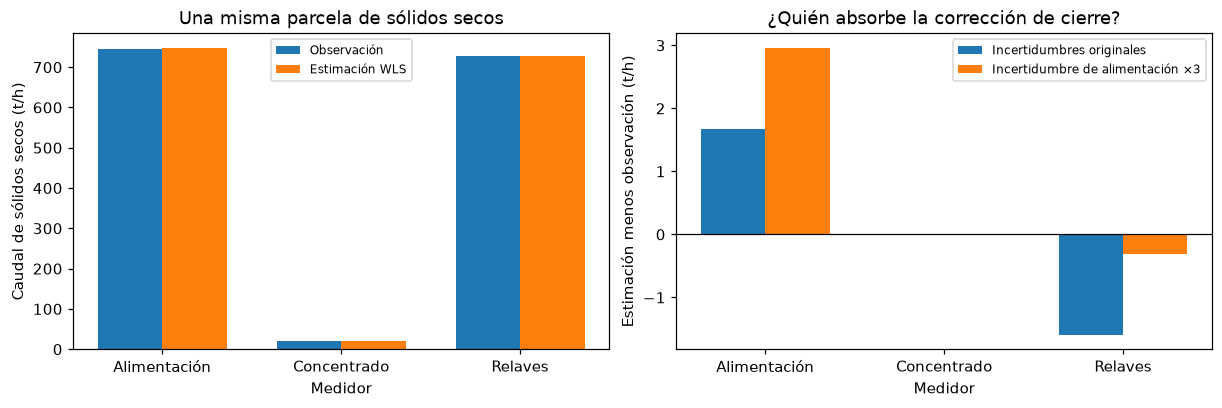

In [5]:
# Graficar los caudales absolutos por separado de los ajustes dependientes de la incertidumbre.
positions = np.arange(3)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), layout="constrained")
axes[0].bar(positions - 0.18, observed, 0.36, label="Observación")
axes[0].bar(positions + 0.18, reconciled["state"], 0.36, label="Estimación WLS")
axes[0].set(title="Una misma parcela de sólidos secos", ylabel="Caudal de sólidos secos (t/h)")
axes[1].bar(positions - 0.18, adjustments[:, 0], 0.36, label="Incertidumbres originales")
axes[1].bar(positions + 0.18, adjustments[:, 1], 0.36, label="Incertidumbre de alimentación ×3")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set(title="¿Quién absorbe la corrección de cierre?", ylabel="Estimación menos observación (t/h)")
for axis in axes:
    axis.set_xticks(positions, ["Alimentación", "Concentrado", "Relaves"])
    axis.set_xlabel("Medidor")
    axis.legend(fontsize=8)
plt.show()

Las barras grandes de la izquierda explican por qué una discrepancia de pocas toneladas por hora cuesta
verla en una vista general. El panel derecho revela su distribución: al confiar menos en alimentación,
ese canal absorbe una mayor corrección. Ningún panel demuestra cuál lectura estaba equivocada. Una ecuación
restringe tres caudales desconocidos; el óptimo ponderado único depende de supuestos que las mediciones por sí
solas no verifican. Un balance cerrado demuestra consistencia y no certifica un instrumento.

Como caso límite conciliamos los caudales nominales del mismo manifiesto. Ya cierran, por lo que una
proyección adecuada debe dejarlos iguales. Así distinguimos imponer una ecuación de conservación de forzar
un nuevo punto operativo arbitrario.

In [6]:
# Examinar el límite físico de una observación que ya está balanceada.
nominal = np.array([trace["channels"][j]["nominal"] for j in columns])
already_closed = weighted_reconcile(nominal, sigma, constraint, [0.0])
print(f"Mayor ajuste nominal: {np.max(np.abs(already_closed['state'] - nominal)):.12f} t/h")
print(f"Rango de la restricción: {already_closed['rank']}; direcciones libres: {len(columns) - already_closed['rank']}")

Mayor ajuste nominal: 0.000000000000 t/h
Rango de la restricción: 1; direcciones libres: 2


## Resultados

**Respuesta:** La parcela seleccionada tiene un residuo observado de alimentación menos productos de
-3.275253 t/h. Con las incertidumbres originales, WLS estima alimentación de 746.692931 t/h, concentrado de
19.381637 t/h y relaves de 727.311294 t/h. Triplicar la incertidumbre de alimentación aumenta su ajuste de
1.679901 a 2.962638 t/h. La parcela nominal cerrada requiere un ajuste de 0.000000000000 t/h. Las cifras
responden cómo se reparte la corrección; no identifican un instrumento defectuoso.

Para reutilizar el cálculo hay que sustituir las tres observaciones, sus incertidumbres estándar calibradas
y la fila adecuada del balance material. No se debe mezclar volumen de pulpa con masa de sólidos secos,
ni asumir que una marca temporal común demuestra que dos medidores observaron la misma parcela. Este
estimador lineal no prohíbe explícitamente caudales negativos; el dominio operativo admisible exige otra
decisión de validación.

## Resumen

La conservación entregó una superficie factible y la incertidumbre seleccionó un punto. Las observaciones
siguieron visibles durante todo el cálculo. Antes de interpretar un ajuste como evidencia de un problema,
la siguiente lección examina dos causas de discrepancia en una planta sana: transporte e inventario variable.

## Referencias

- Sadeghi, Hodouin y Bazin (2018), *Mineral processing plant data reconciliation including mineral mass
  balance constraints*. https://doi.org/10.1016/j.mineng.2018.04.023
- Implementación: `pipeline.model.reconciliation.weighted_reconcile`; canales y retardos:
  `data-pipeline/pipeline/model/scenarios.py`; reproducción: `data/derived/PL-01/trace.json`.